In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

try:
    from river.drift import ADWIN
    HAS_RIVER = True
except ImportError:
    HAS_RIVER = False

In [ ]:
class ADWINFallback:
    
    def __init__(self, delta=0.002, min_window=30, max_window=600):
        self.delta = delta
        self.min_window = min_window
        self.max_window = max_window
        self.window = []
        self.drift_detected = False

    def update(self, val):
        self.drift_detected = False
        if np.isnan(val):
            return self
        self.window.append(float(val))
        if len(self.window) > self.max_window:
            self.window.pop(0)
        n = len(self.window)

        if n >= 2 * self.min_window:
            cut = int(n * 0.7)
            w1 = np.array(self.window[:cut])
            w2 = np.array(self.window[cut:])
            m1, m2 = w1.mean(), w2.mean()
            s_pool = np.sqrt(w1.var(ddof=1) / len(w1) + w2.var(ddof=1) / len(w2) + 1e-12)
            z_diff = abs(m2 - m1) / s_pool
            
            if z_diff > 3.2 and abs(m2 - m1) > 0.35 * (abs(m1) + 0.1):
                self.drift_detected = True
                self.window = list(w2)
                
        return self

=== VERIFICAÇÃO WELFORD VS BATCH (Global_active_power) ===
Média   -> Welford: 1.15445384 | Batch: 1.15445384 | Diff: 2.40e-14
DP (pop)-> Welford: 1.11463092 | Batch: 1.11463092
DP (am.)-> Welford: 1.11463163 | Batch: 1.11463163
Deteções ADWIN (blocos de 15 min) na janela: 916
Total de alarmes (|z| > 3.5, janela 120 min): 22225


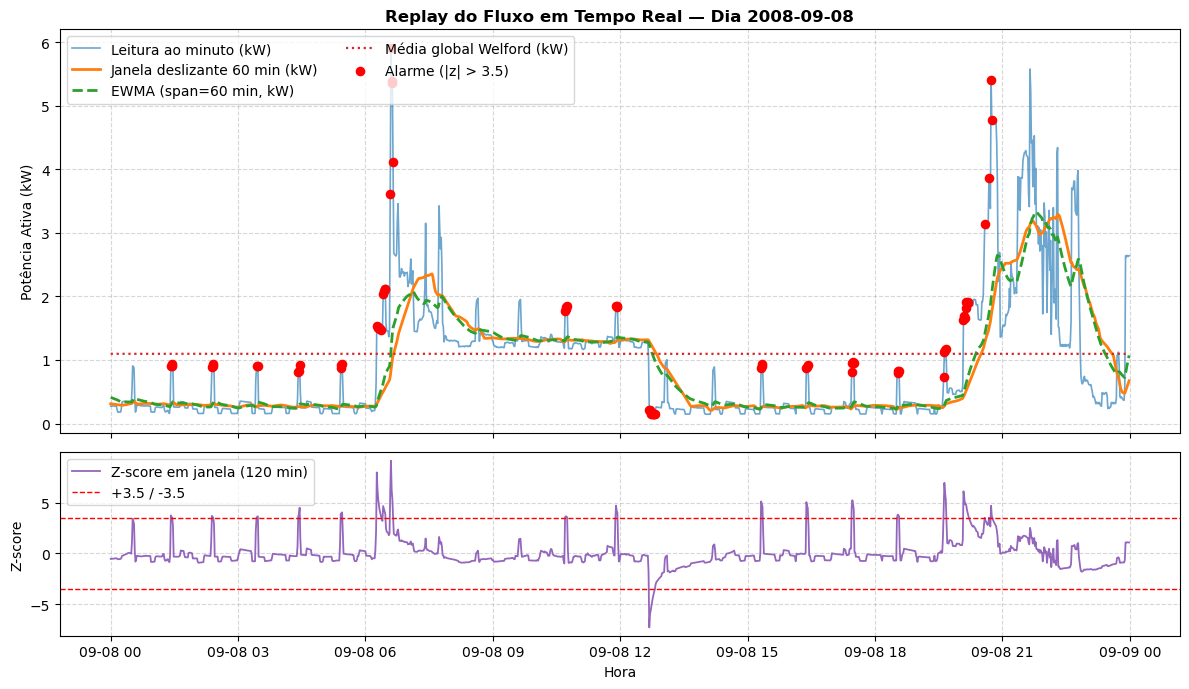

In [ ]:
processed_csv = Path("data/processed/household_power_consumption_tratado.csv")

df = pd.read_csv(
    processed_csv, 
    sep=";", 
    index_col="Datetime", 
    parse_dates=True, 
    low_memory=False
)

serie_fluxo = df["Global_active_power"].astype(float)
timestamps = serie_fluxo.index
valores = serie_fluxo.to_numpy()

n_obs = 0
welford_mean = 0.0
welford_m2 = 0.0

janela_60 = []
alpha_ewma = 2.0 / (60.0 + 1.0)  
ewma_val = np.nan

win_z = 120
limiar_z = 3.5
min_std_z = 0.05
historico_z = []

adwin_15m = ADWIN(delta=0.005) if HAS_RIVER else ADWINFallback(delta=0.005)
buf_15m = []

welford_means_arr = np.full(len(valores), np.nan)
welford_stds_arr = np.full(len(valores), np.nan)
roll60_mean_arr = np.full(len(valores), np.nan)
ewma_arr = np.full(len(valores), np.nan)
zscore_arr = np.zeros(len(valores), dtype=float)
alarme_arr = np.zeros(len(valores), dtype=bool)
drift_15m_timestamps = []

for i in range(len(valores)):
    x = valores[i]
    ts = timestamps[i]

    if np.isnan(x):
        continue

    n_obs += 1
    delta = x - welford_mean
    welford_mean += delta / n_obs
    delta2 = x - welford_mean
    welford_m2 += delta * delta2

    welford_means_arr[i] = welford_mean
    var_pop = (welford_m2 / n_obs) if n_obs > 0 else 0.0
    welford_stds_arr[i] = np.sqrt(max(var_pop, 0.0))

    janela_60.append(x)
    if len(janela_60) > 60:
        janela_60.pop(0)
    roll60_mean_arr[i] = float(np.mean(janela_60))

    if np.isnan(ewma_val):
        ewma_val = float(x)
    else:
        ewma_val = alpha_ewma * float(x) + (1.0 - alpha_ewma) * ewma_val
    ewma_arr[i] = ewma_val

    if len(historico_z) >= 30:
        arr_h = np.array(historico_z, dtype=float)
        mu_h = float(arr_h.mean())
        sd_h = max(float(arr_h.std(ddof=1)), min_std_z)
        z_i = (float(x) - mu_h) / sd_h
        zscore_arr[i] = z_i
        if abs(z_i) > limiar_z:
            alarme_arr[i] = True

    historico_z.append(float(x))
    if len(historico_z) > win_z:
        historico_z.pop(0)

    buf_15m.append(float(x))
    if len(buf_15m) == 15:
        m15 = float(np.mean(buf_15m))
        buf_15m = []
        adwin_15m.update(m15)
        if adwin_15m.drift_detected:
            drift_15m_timestamps.append(ts)

val_validos = serie_fluxo.dropna().to_numpy()
batch_mean = float(np.mean(val_validos))
batch_std_pop = float(np.std(val_validos, ddof=0))
batch_std_samp = float(np.std(val_validos, ddof=1))

welford_std_samp = np.sqrt(welford_m2 / (n_obs - 1)) if n_obs > 1 else 0.0

print("=== VERIFICAÇÃO WELFORD VS BATCH (Global_active_power) ===")
print(f"Média   -> Welford: {welford_mean:.8f} | Batch: {batch_mean:.8f} | Diff: {abs(welford_mean - batch_mean):.2e}")
print(f"DP (pop)-> Welford: {welford_stds_arr[np.where(~np.isnan(welford_stds_arr))[0][-1]]:.8f} | Batch: {batch_std_pop:.8f}")
print(f"DP (am.)-> Welford: {welford_std_samp:.8f} | Batch: {batch_std_samp:.8f}")
print(f"Deteções ADWIN (blocos de 15 min) na janela: {len(drift_15m_timestamps)}")
print(f"Total de alarmes (|z| > {limiar_z}, janela {win_z} min): {int(alarme_arr.sum())}")

df_fluxo_res = pd.DataFrame({
    "x_min": valores,
    "welford_mean": welford_means_arr,
    "roll60_mean": roll60_mean_arr,
    "ewma": ewma_arr,
    "zscore": zscore_arr,
    "alarme": alarme_arr
}, index=timestamps)

alarmes_por_dia = df_fluxo_res[df_fluxo_res["alarme"]].groupby(df_fluxo_res[df_fluxo_res["alarme"]].index.normalize()).size()
dia_alvo = alarmes_por_dia.idxmax() if not alarmes_por_dia.empty else pd.Timestamp("2008-12-10")

dia_prox = dia_alvo + pd.Timedelta(days=1)
sub_dia = df_fluxo_res.loc[(df_fluxo_res.index >= dia_alvo) & (df_fluxo_res.index < dia_prox)]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})

ax1.plot(sub_dia.index, sub_dia["x_min"], label="Leitura ao minuto (kW)", alpha=0.65, linewidth=1.2)
ax1.plot(sub_dia.index, sub_dia["roll60_mean"], label="Janela deslizante 60 min (kW)", linewidth=2.0)
ax1.plot(sub_dia.index, sub_dia["ewma"], label="EWMA (span=60 min, kW)", linewidth=2.0, linestyle="--")
ax1.plot(sub_dia.index, sub_dia["welford_mean"], label="Média global Welford (kW)", linewidth=1.6, linestyle=":")

pts_al = sub_dia[sub_dia["alarme"]]
if not pts_al.empty:
    ax1.scatter(pts_al.index, pts_al["x_min"], color="red", zorder=5, s=35, label=f"Alarme (|z| > {limiar_z})")

ax1.set_title(f"Replay do Fluxo em Tempo Real — Dia {dia_alvo:%Y-%m-%d}", fontweight="bold")
ax1.set_ylabel("Potência Ativa (kW)")
ax1.legend(loc="upper left", ncol=2, frameon=True)
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(sub_dia.index, sub_dia["zscore"], color="tab:purple", linewidth=1.3, label="Z-score em janela (120 min)")
ax2.axhline(limiar_z, color="red", linestyle="--", linewidth=1.0, label=f"+{limiar_z} / -{limiar_z}")
ax2.axhline(-limiar_z, color="red", linestyle="--", linewidth=1.0)
ax2.set_ylabel("Z-score")
ax2.set_xlabel("Hora")
ax2.legend(loc="upper left", frameon=True)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
indices_alarme = np.flatnonzero(alarme_arr)
if len(indices_alarme) > 0:
    escolhidos = indices_alarme[np.linspace(0, len(indices_alarme) - 1, min(5, len(indices_alarme)), dtype=int)]
    linhas_5 = []
    for idx in escolhidos:
        t_al = timestamps[idx]
        x_al = valores[idx]
        z_al = zscore_arr[idx]
        
        pos_15 = valores[idx:min(idx + 15, len(valores))]
        m_pos15 = float(np.nanmean(pos_15)) if len(pos_15) > 0 else np.nan
        
        if abs(x_al - m_pos15) > 0.6 * max(x_al, 0.2):
            tipo_sugerido = "Candidato a falso/transiente (rápida reversão em 15 min)"
        else:
            tipo_sugerido = "Candidato a real (mudança/pico mantido nos 15 min seguintes)"
        linhas_5.append({
            "Instante": t_al,
            "Valor_kW": round(float(x_al), 3),
            "Z_score": round(float(z_al), 2),
            "Media_prox_15m_kW": round(m_pos15, 3),
            "Avaliacao_qualitativa_inicial": tipo_sugerido
        })
    print("\n=== AMOSTRA DE ATÉ 5 ALARMES PARA AVALIAÇÃO QUALITATIVA ===")
    display(pd.DataFrame(linhas_5))


=== AMOSTRA DE ATÉ 5 ALARMES PARA AVALIAÇÃO QUALITATIVA ===


,Instante,Valor_kW,Z_score,Media_prox_15m_kW,Avaliacao_qualitativa_inicial
0,2007-10-01 06:37:00,0.506,3.98,1.197,Candidato a falso/transiente (rápida reversão ...
1,2008-02-25 15:53:00,1.324,8.55,1.325,Candidato a real (mudança/pico mantido nos 15 ...
2,2008-07-08 15:27:00,0.912,3.70,0.359,Candidato a falso/transiente (rápida reversão ...
3,2008-11-07 04:52:00,1.416,4.03,1.385,Candidato a real (mudança/pico mantido nos 15 ...
4,2009-03-31 20:35:00,6.524,3.54,5.562,Candidato a real (mudança/pico mantido nos 15 ...
